# YOLO26n-Seg


## 1. Environment and imports

In [1]:
%pip install -q ultralytics==8.4.215 pycocotools "supervision[metrics]==0.31.3"


Note: you may need to restart the kernel to use updated packages.


In [2]:
import csv
import json
import shutil
import subprocess
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

import torch

## 2. Dataset configuration and checks

In [3]:
root = Path("/kaggle/input/datasets/paibarrr/panoptic-indoor-segmentation-coco/")
train = root / "train"
valid = root / "valid"
test = root / "test"
dst = Path("/kaggle/working/yolo26n_seg_runs")
DATASET_DIR = root
OUTPUT_DIR = dst
CHECKPOINT_DIR = dst
RUN_TRAINING = True
RESUME_PRETRAINED = None
RESUME_SCRATCH = None
EPOCHS = 50
GPU_COUNT = 2

assert torch.cuda.is_available(), "Enable a Kaggle GPU accelerator."
assert torch.cuda.device_count() >= GPU_COUNT, "Select the Kaggle dual T4 GPU accelerator."

print(f"Dataset: {DATASET_DIR}")
print(f"GPUs: {torch.cuda.device_count()}")
for gpu_index in range(torch.cuda.device_count()):
    print(f"GPU {gpu_index}: {torch.cuda.get_device_name(gpu_index)}")

Dataset: /kaggle/input/datasets/paibarrr/panoptic-indoor-segmentation-coco
GPUs: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


In [4]:
for split, split_dir in (("train", train), ("valid", valid), ("test", test)):
    annotation_file = split_dir / "_annotations.coco.json"
    annotations = json.loads(annotation_file.read_text())
    print(f"{split}: {len(annotations['images'])} images, {len(annotations['annotations'])} annotations")

train_annotations = json.loads((train / "_annotations.coco.json").read_text())
print(f"Classes: {len(train_annotations['categories'])}")

train: 397 images, 4479 annotations
valid: 166 images, 2022 annotations
test: 359 images, 5344 annotations
Classes: 75


## 3. Output directories and artifacts

In [5]:
ARTIFACT_DIR = OUTPUT_DIR / "report_artifacts"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

class_distribution = []
dataset_summary = {"dataset_dir": str(DATASET_DIR), "splits": {}, "classes": train_annotations["categories"]}

for split, split_dir in (("train", train), ("valid", valid), ("test", test)):
    annotation_data = json.loads((split_dir / "_annotations.coco.json").read_text())
    category_names = {item["id"]: item["name"] for item in annotation_data["categories"]}
    instance_counts = {category_id: 0 for category_id in category_names}
    for annotation in annotation_data["annotations"]:
        instance_counts[annotation["category_id"]] += 1
    dataset_summary["splits"][split] = {
        "images": len(annotation_data["images"]),
        "annotations": len(annotation_data["annotations"]),
    }
    class_distribution.extend([
        {"split": split, "class_id": category_id, "class_name": category_names[category_id], "instances": count}
        for category_id, count in instance_counts.items()
    ])

(ARTIFACT_DIR / "dataset_summary.json").write_text(json.dumps(dataset_summary, indent=2), encoding="utf-8")
(ARTIFACT_DIR / "class_names.json").write_text(
    json.dumps([item["name"] for item in train_annotations["categories"]], indent=2),
    encoding="utf-8",
)
with (ARTIFACT_DIR / "class_distribution.csv").open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=["split", "class_id", "class_name", "instances"])
    writer.writeheader()
    writer.writerows(class_distribution)



In [6]:
import shutil
from PIL import Image
from ultralytics.data.converter import convert_coco
from ultralytics.utils import YAML

YOLO_ANNOTATIONS = Path("/kaggle/working/yolo_annotations")
YOLO_CONVERTED = Path("/kaggle/working/yolo_converted")
YOLO_DATA_DIR = Path("/kaggle/working/yolo_dataset")
YOLO_DATA_YAML = YOLO_DATA_DIR / "dataset.yaml"

for directory in (YOLO_ANNOTATIONS, YOLO_CONVERTED, YOLO_DATA_DIR):
    shutil.rmtree(directory, ignore_errors=True)
YOLO_ANNOTATIONS.mkdir(parents=True)
categories = sorted(train_annotations["categories"], key=lambda item: item["id"])
class_names = {index: item["name"] for index, item in enumerate(categories)}

for split in ("train", "valid", "test"):
    split_dir = {"train": train, "valid": valid, "test": test}[split]
    coco_data = json.loads((split_dir / "_annotations.coco.json").read_text())
    category_id_by_name = {
        category["name"]: index + 1
        for index, category in enumerate(categories)
    }
    category_id_map = {}
    for category in coco_data["categories"]:
        if category["name"] not in category_id_by_name:
            raise ValueError(f"Unknown dataset class: {category['name']}")
        category_id_map[category["id"]] = category_id_by_name[category["name"]]
        category["id"] = category_id_map[category["id"]]
    for annotation in coco_data["annotations"]:
        annotation["category_id"] = category_id_map[annotation["category_id"]]
    coco_data["categories"] = [
        {"id": category_id_by_name[category["name"]], "name": category["name"]}
        for category in categories
    ]
    (YOLO_ANNOTATIONS / f"instances_{split}.json").write_text(json.dumps(coco_data))

convert_coco(
    labels_dir=str(YOLO_ANNOTATIONS),
    save_dir=str(YOLO_CONVERTED),
    use_segments=True,
    cls91to80=False,
)

for split in ("train", "valid", "test"):
    split_dir = {"train": train, "valid": valid, "test": test}[split]
    image_dir = YOLO_DATA_DIR / "images" / split
    label_dir = YOLO_DATA_DIR / "labels" / split
    image_dir.mkdir(parents=True)
    shutil.copytree(YOLO_CONVERTED / "labels" / split, label_dir)
    coco_data = json.loads((split_dir / "_annotations.coco.json").read_text())
    for image_info in coco_data["images"]:
        image_file = split_dir / image_info["file_name"]
        with Image.open(image_file) as image:
            if image.size == (image_info["height"], image_info["width"]) and image.width != image.height:
                image.transpose(Image.Transpose.ROTATE_270).save(image_dir / image_file.name, quality=95)
            else:
                shutil.copy2(image_file, image_dir / image_file.name)

YAML.save(
    str(YOLO_DATA_YAML),
    {
        "path": str(YOLO_DATA_DIR),
        "train": "images/train",
        "val": "images/valid",
        "test": "images/test",
        "names": class_names,
    },
)
print(YOLO_DATA_YAML)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Annotations /kaggle/working/yolo_annotations/instances_test.json: 100% ━━━━━━━━━━━━ 359/359 1.2Kit/s 0.3s
Annotations /kaggle/working/yolo_annotations/instances_train.json: 100% ━━━━━━━━━━━━ 397/397 1.6Kit/s 0.2s
Annotations /kaggle/working/yolo_annotations/instances_valid.json: 100% ━━━━━━━━━━━━ 165/165 1.5Kit/s 0.1s
COCO data converted successfully.
Results saved to /kaggle/working/yolo_converted
/kaggle/working/yolo_dataset/dataset.yaml


## 4. Model setup

In [7]:
from ultralytics import YOLO


def run_yolo(weights, resume_checkpoint=None):
    run_dir = OUTPUT_DIR / "yolo" / weights
    run_dir.mkdir(parents=True, exist_ok=True)
    started_at = datetime.now(timezone.utc).isoformat()
    start_time = time.perf_counter()
    status = "failed"

    try:
        if resume_checkpoint:
            checkpoint = torch.load(resume_checkpoint, map_location="cpu", weights_only=False)
            if checkpoint.get("optimizer") is None or checkpoint.get("epoch", -1) < 0:
                raise ValueError("Resume requires a full epoch checkpoint with optimizer state.")
            if EPOCHS <= checkpoint["epoch"] + 1:
                raise ValueError("EPOCHS must be greater than the checkpoint epoch.")
            resume_file = run_dir / "resume_full.pt"
            checkpoint["train_args"]["epochs"] = EPOCHS
            checkpoint["train_args"]["data"] = str(YOLO_DATA_YAML)
            checkpoint["train_args"]["save_dir"] = str(run_dir)
            torch.save(checkpoint, resume_file)
            model = YOLO(str(resume_file))
            result = model.train(resume=True, data=str(YOLO_DATA_YAML), device=[0, 1], workers=2, save_period=1)
        else:
            model_file = "yolo26n-seg.pt" if weights == "pretrained" else "yolo26n-seg.yaml"
            model = YOLO(model_file)
            result = model.train(
                data=str(YOLO_DATA_YAML),
                epochs=EPOCHS,
                imgsz=640,
                batch=16,
                device=[0, 1],
                workers=2,
                seed=42,
                project=str(OUTPUT_DIR / "yolo"),
                name=weights,
                exist_ok=True,
                save=True,
                save_period=1,
                plots=True,
                verbose=True,
                freeze=None,
            )
        status = "completed"
        return result
    finally:
        metadata = {
            "model": "YOLO26n-seg",
            "weights": weights,
            "status": status,
            "started_at_utc": started_at,
            "elapsed_wall_seconds": round(time.perf_counter() - start_time, 2),
            "dataset_dir": str(DATASET_DIR),
            "train_images": len(train_annotations["images"]),
            "classes": len(train_annotations["categories"]),
            "epochs": EPOCHS,
            "image_size": 640,
            "batch_size": 16,
            "seed": 42,
            "strategy": "DDP",
            "gpu_names": [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())],
            "training_log": str(run_dir / "results.csv"),
            "resume_checkpoint": str(run_dir / "weights" / f"epoch{EPOCHS - 1}.pt"),
            "resumed_from": str(resume_checkpoint or ""),
            "inference_checkpoint": str(run_dir / "weights" / "best.pt"),
        }
        (run_dir / "run_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
        (ARTIFACT_DIR / f"yolo_{weights}_run_metadata.json").write_text(
            json.dumps(metadata, indent=2), encoding="utf-8"
        )


## 5. Training runs

In [8]:
if RUN_TRAINING:
    run_yolo("pretrained", RESUME_PRETRAINED)


New https://pypi.org/project/ultralytics/8.4.216 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/yolo_dataset/dataset.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=Non

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   seg_loss   cls_loss    l1_loss   sem_loss  Instances       Size
       2/50      7.82G      1.325      2.526      4.857    0.01283      5.566        243        640: 100% ━━━━━━━━━━━━ 25/25 2.6it/s 9.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 3.2it/s 1.9s
                   all        166       2021      0.659      0.222      0.147      0.112      0.655      0.203      0.142     0.0959

      Epoch    GPU_mem   box_loss   seg_loss   cls_loss    l1_loss   sem_loss  Instances       Size
       3/50      6.71G      1.232      2.369      4.672    0.01261       5.31        175        640: 100% ━━━━━━━━━━━━ 25/25 2.7it/s 9.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 3.3it/s 1.8s
                   all        166       2021      0

In [9]:
if RUN_TRAINING:
    run_yolo("scratch", RESUME_SCRATCH)


New https://pypi.org/project/ultralytics/8.4.216 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/yolo_dataset/dataset.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=Non

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   seg_loss   cls_loss    l1_loss   sem_loss  Instances       Size
       2/50      6.38G      3.938      9.189      5.901    0.05444      6.343        243        640: 100% ━━━━━━━━━━━━ 25/25 2.7it/s 9.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 3.8it/s 1.6s
                   all        166       2021          0          0          0          0          0          0          0          0

      Epoch    GPU_mem   box_loss   seg_loss   cls_loss    l1_loss   sem_loss  Instances       Size
       3/50      6.38G      3.899      6.834      5.774    0.05438      6.315        175        640: 100% ━━━━━━━━━━━━ 25/25 2.7it/s 9.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 3.9it/s 1.5s
                   all        166       2021       

## 6. Inference and evaluation

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n-seg summary (fused): 137 layers, 2,721,765 parameters, 0 gradients, 9.2 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1169.2±778.8 MB/s, size: 50.6 KB)
val: Scanning /kaggle/working/yolo_dataset/labels/test... 359 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 359/359 764.2it/s 0.5s
val: New cache created: /kaggle/working/yolo_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 4.3it/s 5.4s
                   all        359       5341      0.465      0.225      0.203      0.145      0.445      0.219      0.193      0.124
              backpack         15         31      0.747     0.0968      0.216     0.0885      0.736     0.0968      0.216      0.119
                   bed         58         71      0.254      0.634      0.557      0.254      0.249 

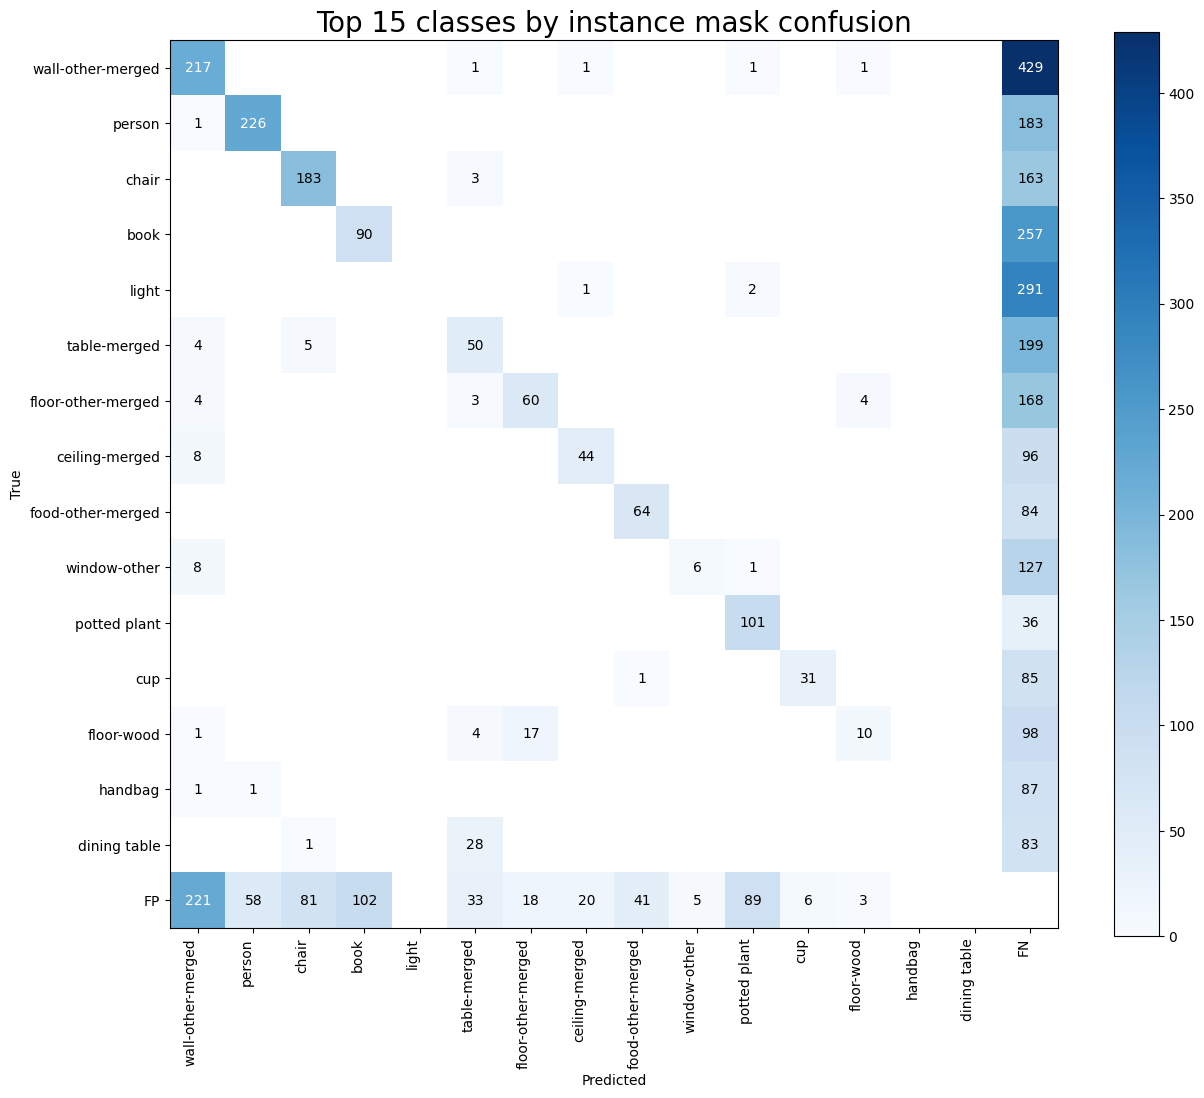

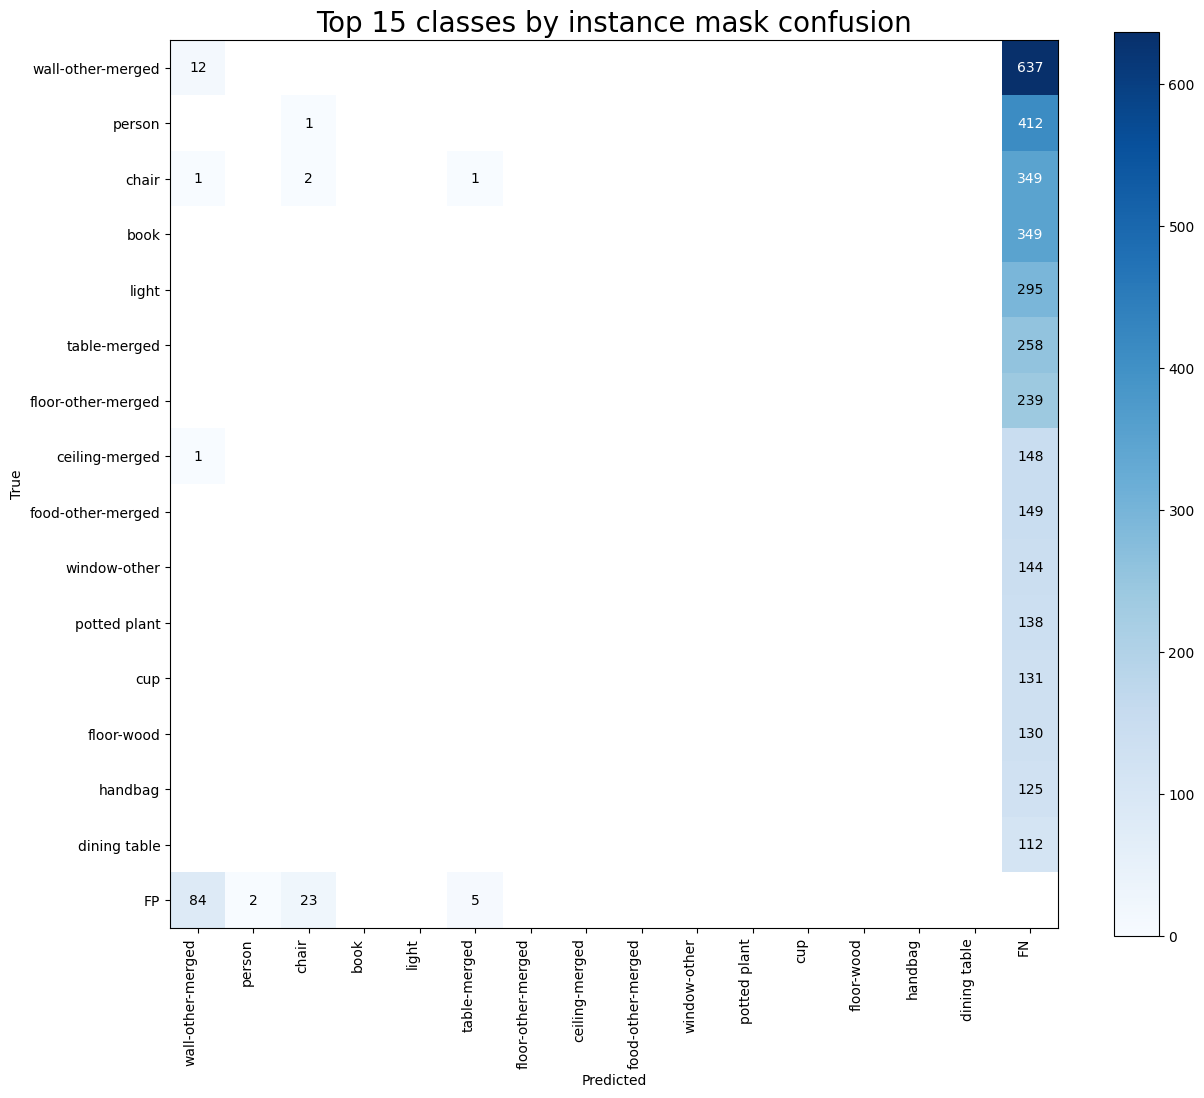

In [10]:
from ultralytics import YOLO
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from pycocotools.coco import COCO
import supervision as sv
from supervision.metrics import MetricTarget

CLASS_NAMES = [item["name"] for item in sorted(train_annotations["categories"], key=lambda item: item["id"])]
BACKGROUND_INDEX = len(CLASS_NAMES)


def save_yolo_metrics(metrics, output_dir):
    output_dir.mkdir(parents=True, exist_ok=True)
    values = {key: float(value) for key, value in metrics.results_dict.items()}
    (output_dir / "metrics.json").write_text(json.dumps(values, indent=2), encoding="utf-8")
    return values




def yolo_masks_and_labels(result, height, width):
    if result.masks is None:
        return np.zeros((0, height, width), dtype=bool), np.zeros(0, dtype=int), np.zeros(0)

    masks = result.masks.data.cpu().numpy()
    labels = result.boxes.cls.cpu().numpy().astype(int)
    scores = result.boxes.conf.cpu().numpy()
    resized_masks = []
    for mask in masks:
        if mask.shape != (height, width):
            mask = np.asarray(
                Image.fromarray(mask.astype(np.uint8)).resize(
                    (width, height), Image.Resampling.NEAREST
                )
            )
        resized_masks.append(mask.astype(bool))
    return np.asarray(resized_masks), labels, scores


def render_yolo_masks(image, masks, labels, scores=None):
    overlay = image.copy()
    colors = plt.get_cmap("tab20")
    for index, mask in enumerate(masks):
        class_index = int(labels[index])
        color = (np.asarray(colors(class_index % 20)[:3]) * 255).astype(np.uint8)
        overlay[mask] = (0.45 * overlay[mask] + 0.55 * color).astype(np.uint8)
    rendered = Image.fromarray(overlay)
    draw = ImageDraw.Draw(rendered)
    for index, class_index in enumerate(labels):
        label = CLASS_NAMES[int(class_index)]
        if scores is not None:
            label += f" {float(scores[index]):.2f}"
        draw.text((8, 8 + index * 18), label, fill="white", stroke_width=1, stroke_fill="black")
    return rendered


def make_coco_detections(annotations, coco, category_name_by_id, class_index_by_name):
    if not annotations:
        return sv.Detections.empty()

    boxes = np.asarray(
        [[x, y, x + width, y + height] for x, y, width, height in (item["bbox"] for item in annotations)],
        dtype=np.float32,
    )
    masks = np.asarray([coco.annToMask(item).astype(bool) for item in annotations])
    labels = np.asarray(
        [class_index_by_name[category_name_by_id[item["category_id"]]] for item in annotations],
        dtype=int,
    )
    return sv.Detections(xyxy=boxes, mask=masks, class_id=labels)


def save_mask_confusion(matrix, output_dir):
    labels = CLASS_NAMES + ["background"]
    with (output_dir / "mask_confusion_matrix.csv").open("w", newline="", encoding="utf-8") as file:
        writer = csv.writer(file)
        writer.writerow(["ground_truth / prediction", *labels])
        for label, row in zip(labels, matrix):
            writer.writerow([label, *row.tolist()])

    top_classes = sorted(range(len(CLASS_NAMES)), key=lambda index: matrix[index].sum(), reverse=True)[:15]
    visible_order = top_classes + [BACKGROUND_INDEX]
    display_matrix = sv.ConfusionMatrix(
        matrix=matrix[np.ix_(visible_order, visible_order)].astype(np.int32),
        classes=[CLASS_NAMES[index] for index in top_classes],
        conf_threshold=0.25,
        iou_threshold=0.5,
        metric_target=MetricTarget.MASKS,
    )
    display_matrix.plot(
        save_path=str(output_dir / "mask_confusion_matrix_top15.png"),
        title="Top 15 classes by instance mask confusion",
        fig_size=(13, 11),
    )


def save_yolo_mask_analysis(model, split_dir, output_dir, max_images=12):
    annotation_file = split_dir / "_annotations.coco.json"
    annotation_data = json.loads(annotation_file.read_text())
    coco = COCO(str(annotation_file))
    category_name_by_id = {item["id"]: item["name"] for item in annotation_data["categories"]}
    class_index_by_name = {name: index for index, name in enumerate(CLASS_NAMES)}
    confusion = np.zeros((len(CLASS_NAMES) + 1, len(CLASS_NAMES) + 1), dtype=np.int64)
    sample_dirs = {
        "inputs": output_dir / "sample_inputs",
        "ground_truth": output_dir / "sample_ground_truth",
        "predictions": output_dir / "sample_predictions",
    }
    for directory in sample_dirs.values():
        directory.mkdir(parents=True, exist_ok=True)
    failure_rows = []

    for sample_index, image_info in enumerate(annotation_data["images"]):
        image_path = split_dir / image_info["file_name"]
        image = np.asarray(Image.open(image_path).convert("RGB"))
        height, width = image.shape[:2]
        result = model.predict(str(image_path), conf=0.25, retina_masks=True, verbose=False)[0]
        prediction_masks, prediction_labels, prediction_scores = yolo_masks_and_labels(result, height, width)
        annotations = [
            item for item in coco.loadAnns(coco.getAnnIds(imgIds=[image_info["id"]]))
            if not item.get("iscrowd", 0)
        ]
        ground_truth_masks = [coco.annToMask(item).astype(bool) for item in annotations]
        ground_truth_labels = [
            class_index_by_name[category_name_by_id[item["category_id"]]]
            for item in annotations
        ]
        ground_truth_detections = make_coco_detections(
            annotations, coco, category_name_by_id, class_index_by_name
        )
        prediction_detections = (
            sv.Detections(
                xyxy=result.boxes.xyxy.cpu().numpy(),
                mask=prediction_masks,
                class_id=prediction_labels,
                confidence=prediction_scores,
            )
            if len(prediction_labels)
            else sv.Detections.empty()
        )
        image_confusion = sv.ConfusionMatrix.from_detections(
            predictions=[prediction_detections],
            targets=[ground_truth_detections],
            classes=CLASS_NAMES,
            conf_threshold=0.25,
            iou_threshold=0.5,
            metric_target=MetricTarget.MASKS,
        ).matrix
        confusion += image_confusion
        matched_classes = image_confusion[:-1, :-1]
        false_positives = int(image_confusion[-1, :-1].sum())
        false_negatives = int(image_confusion[:-1, -1].sum())
        class_mismatches = int(matched_classes.sum() - np.trace(matched_classes))
        failure_rows.append({
            "image": image_info["file_name"],
            "false_positives": false_positives,
            "false_negatives": false_negatives,
            "class_mismatches": class_mismatches,
            "total_errors": false_positives + false_negatives + class_mismatches,
        })
        if sample_index < max_images:
            shutil.copy2(image_path, sample_dirs["inputs"] / image_path.name)
            render_yolo_masks(
                image,
                ground_truth_masks,
                ground_truth_labels,
            ).save(sample_dirs["ground_truth"] / image_path.name)
            render_yolo_masks(
                image,
                prediction_masks,
                prediction_labels,
                prediction_scores,
            ).save(sample_dirs["predictions"] / image_path.name)

    save_mask_confusion(confusion, output_dir)

    failure_rows.sort(key=lambda row: row["total_errors"], reverse=True)
    with (output_dir / "failure_candidates.csv").open("w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(
            file,
            fieldnames=["image", "false_positives", "false_negatives", "class_mismatches", "total_errors"],
        )
        writer.writeheader()
        writer.writerows(failure_rows)

    failure_dirs = {
        "inputs": output_dir / "failure_examples" / "inputs",
        "ground_truth": output_dir / "failure_examples" / "ground_truth",
        "predictions": output_dir / "failure_examples" / "predictions",
    }
    for directory in failure_dirs.values():
        directory.mkdir(parents=True, exist_ok=True)
    image_info_by_name = {item["file_name"]: item for item in annotation_data["images"]}
    for failure in failure_rows[:5]:
        image_info = image_info_by_name[failure["image"]]
        image_path = split_dir / image_info["file_name"]
        image = np.asarray(Image.open(image_path).convert("RGB"))
        height, width = image.shape[:2]
        result = model.predict(str(image_path), conf=0.25, retina_masks=True, verbose=False)[0]
        prediction_masks, prediction_labels, prediction_scores = yolo_masks_and_labels(result, height, width)
        annotations = [
            item for item in coco.loadAnns(coco.getAnnIds(imgIds=[image_info["id"]]))
            if not item.get("iscrowd", 0)
        ]
        ground_truth_masks = [coco.annToMask(item).astype(bool) for item in annotations]
        ground_truth_labels = [
            class_index_by_name[category_name_by_id[item["category_id"]]]
            for item in annotations
        ]
        shutil.copy2(image_path, failure_dirs["inputs"] / image_path.name)
        render_yolo_masks(image, ground_truth_masks, ground_truth_labels).save(
            failure_dirs["ground_truth"] / image_path.name
        )
        render_yolo_masks(image, prediction_masks, prediction_labels, prediction_scores).save(
            failure_dirs["predictions"] / image_path.name
        )


evaluation_rows = []


def evaluate_yolo(weights):
    checkpoint = CHECKPOINT_DIR / "yolo" / weights / "weights" / "best.pt"
    model = YOLO(str(checkpoint))
    evaluation_dir = ARTIFACT_DIR / "yolo" / weights / "original_test"
    metrics = model.val(
        data=str(YOLO_DATA_YAML),
        split="test",
        plots=False,
        project=str(evaluation_dir.parent),
        name=evaluation_dir.name,
        exist_ok=True,
        verbose=True,
    )
    values = save_yolo_metrics(metrics, evaluation_dir)
    save_yolo_mask_analysis(model, test, evaluation_dir)
    evaluation_rows.append({"weights": weights, "split": "original_test", **values})
    return values


original_test_metrics = {
    weights: evaluate_yolo(weights)
    for weights in ("pretrained", "scratch")
}

with (ARTIFACT_DIR / "yolo_metrics_summary.csv").open("w", newline="", encoding="utf-8") as file:
    fieldnames = ["weights", "split", *sorted({key for row in evaluation_rows for key in row if key not in {"weights", "split"}})]
    writer = csv.DictWriter(file, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(evaluation_rows)
